Dataset Shape: (12294, 7)

First 3 rows:
    anime_id                              name  \
0     32281                    Kimi no Na wa.   
1      5114  Fullmetal Alchemist: Brotherhood   
2     28977                          Gintama°   

                                               genre   type episodes  rating  \
0               Drama, Romance, School, Supernatural  Movie        1    9.37   
1  Action, Adventure, Drama, Fantasy, Magic, Mili...     TV       64    9.26   
2  Action, Comedy, Historical, Parody, Samurai, S...     TV       51    9.25   

   members  
0   200630  
1   793665  
2   114262  

Missing Values:
 anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

Dataset shape after handling missing values: (12017, 7)


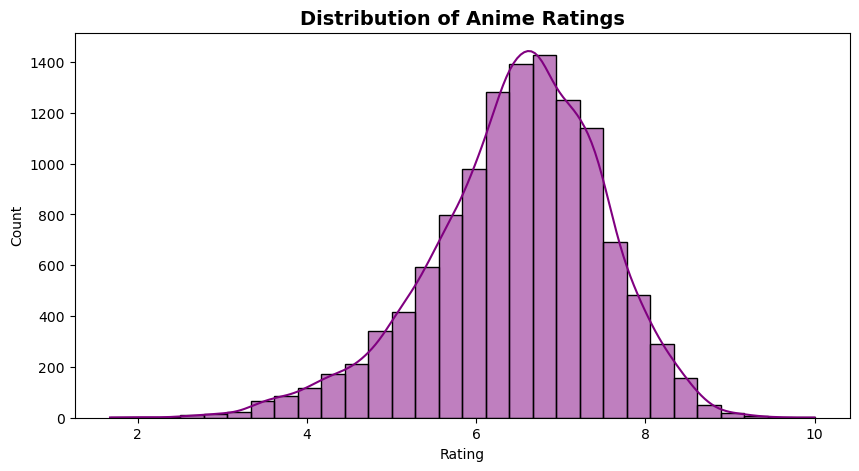

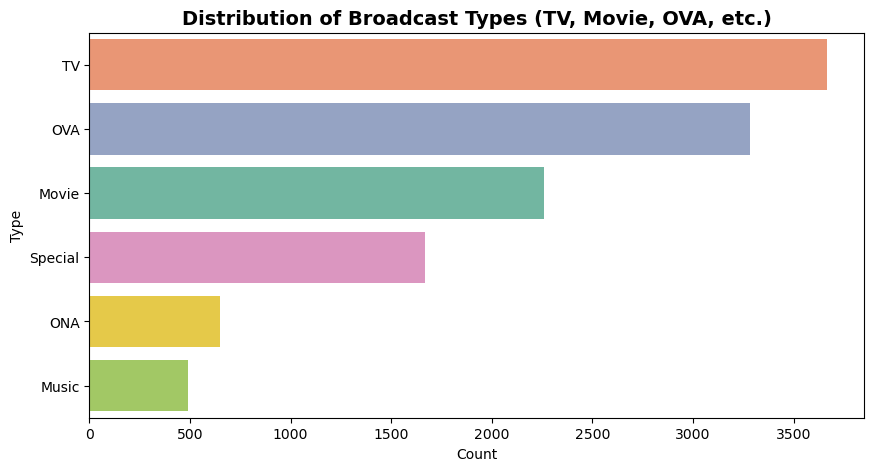

In [5]:
# Recommendation System
# Step 1: Data Preprocessing & EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('anime.csv')
print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))

# 2. Check for missing values
print("\nMissing Values:\n", df.isnull().sum())

# Drop rows with missing genres or ratings to keep the recommendation matrix clean
df = df.dropna(subset=['genre', 'rating', 'type']).reset_index(drop=True)
print("\nDataset shape after handling missing values:", df.shape)

# 3. Exploratory Data Analysis (EDA)
plt.figure(figsize=(10, 5))
sns.histplot(df['rating'], bins=30, kde=True, color='purple')
plt.title('Distribution of Anime Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(
    y='type', 
    data=df, 
    order=df['type'].value_counts().index, 
    hue='type', 
    palette='Set2', 
    legend=False
)
plt.title('Distribution of Broadcast Types (TV, Movie, OVA, etc.)', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Type')
plt.show()

In [2]:
#Step 2: Feature Extraction
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import hstack

# 1. Convert genres into numerical representations via TF-IDF
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['genre'])

# 2. Normalize numerical features (Rating and Members count)
scaler = MinMaxScaler()
num_features = scaler.fit_transform(df[['rating', 'members']])

# 3. Combine TF-IDF text features and normalized numerical features into a single sparse matrix
combined_features = hstack([tfidf_matrix, num_features])
print("Combined feature matrix shape:", combined_features.shape)

Combined feature matrix shape: (12017, 48)


In [3]:
#Step 3: Recommendation System (Cosine Similarity)
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity matrix
cosine_sim = cosine_similarity(combined_features, combined_features)

# Design recommendation function with similarity threshold
def recommend_anime(title, cosine_sim=cosine_sim, df=df, top_n=5, threshold=0.3):
    if title not in df['name'].values:
        return f"Anime '{title}' not found in dataset."
    
    # Get index of the target anime
    idx = df[df['name'] == title].index[0]
    
    # Get similarity scores for all anime with the target anime
    sim_scores = list(enumerate(cosine_sim[idx]))
    
    # Sort by similarity score descending (excluding itself at index 0)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # Filter by threshold and top_n
    filtered_scores = [score for score in sim_scores[1:] if score[1] >= threshold]
    top_scores = filtered_scores[:top_n]
    
    anime_indices = [i[0] for i in top_scores]
    similarity_values = [i[1] for i in top_scores]
    
    # Create result dataframe
    recommendations = pd.DataFrame({
        'Anime Name': df['name'].iloc[anime_indices].values,
        'Genre': df['genre'].iloc[anime_indices].values,
        'Rating': df['rating'].iloc[anime_indices].values,
        'Similarity Score': similarity_values
    })
    
    return recommendations

# Test the recommendation system
print("\n--- Recommendations for 'Kimi no Na wa.' ---")
display(recommend_anime('Kimi no Na wa.', top_n=5, threshold=0.2))

print("\n--- Recommendations for 'Fullmetal Alchemist: Brotherhood' ---")
display(recommend_anime('Fullmetal Alchemist: Brotherhood', top_n=5, threshold=0.2))


--- Recommendations for 'Kimi no Na wa.' ---


,Anime Name,Genre,Rating,Similarity Score
0,Wind: A Breath of Heart OVA,"Drama, Romance, School, Supernatural",6.35,0.962833
1,Wind: A Breath of Heart (TV),"Drama, Romance, School, Supernatural",6.14,0.958903
2,Aura: Maryuuin Kouga Saigo no Tatakai,"Comedy, Drama, Romance, School, Supernatural",7.67,0.958629
3,Shakugan no Shana II (Second),"Action, Drama, Fantasy, Romance, School, Super...",7.79,0.917739
4,Angel Beats!: Another Epilogue,"Drama, School, Supernatural",7.63,0.916605



--- Recommendations for 'Fullmetal Alchemist: Brotherhood' ---


,Anime Name,Genre,Rating,Similarity Score
0,Fullmetal Alchemist,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",8.33,0.982175
1,Fairy Tail,"Action, Adventure, Comedy, Fantasy, Magic, Sho...",8.22,0.879348
2,Fullmetal Alchemist: The Sacred Star of Milos,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",7.50,0.877917
3,Fullmetal Alchemist: Brotherhood Specials,"Adventure, Drama, Fantasy, Magic, Military, Sh...",8.11,0.865544
4,Magi: The Labyrinth of Magic,"Action, Adventure, Fantasy, Magic, Shounen",8.24,0.852996


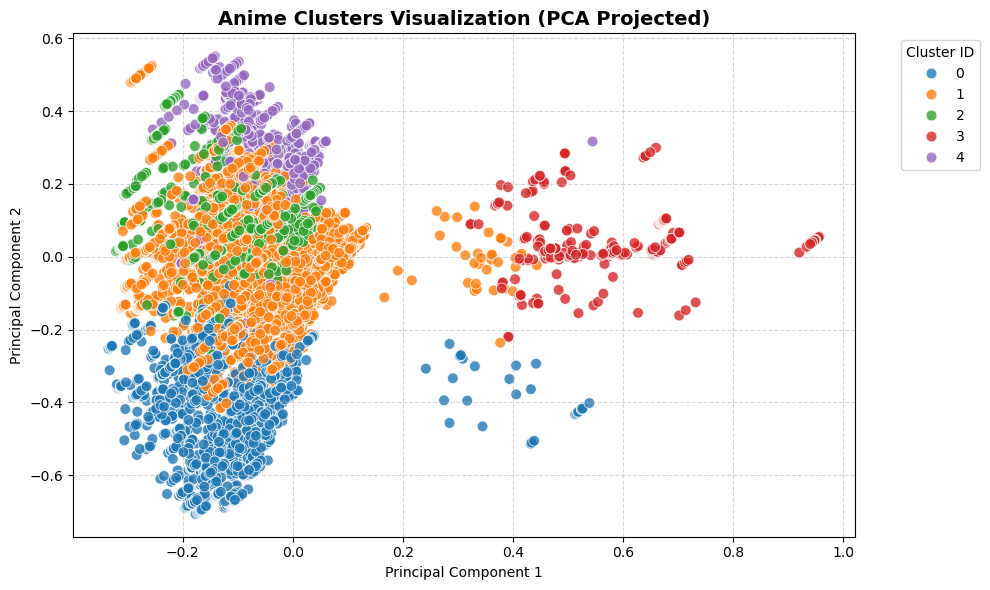

Silhouette Score for K-Means (K=5): 0.1753

--- Sample Anime per Cluster ---
Cluster 0: ['Gintama°', 'Steins;Gate', 'Gintama&#039;']
Cluster 1: ['Kimi no Na wa.', 'Fullmetal Alchemist: Brotherhood', 'Haikyuu!!: Karasuno Koukou VS Shiratorizawa Gakuen Koukou']
Cluster 2: ['Omae Umasou da na', 'Yume-iro Pâtissière', 'Madang-Eul Naon Amtalg']
Cluster 3: ['Oni Chichi: Re-born', 'Mankitsu Happening', 'Koiito Kinenbi The Animation']
Cluster 4: ['Clannad: After Story', 'Mushishi Zoku Shou 2nd Season', 'Ookami Kodomo no Ame to Yuki']


In [4]:
#Step 4 Code: Visualization & Evaluation
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Apply K-Means clustering on our combined anime features (e.g., k=5 groups)
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(combined_features)

# 2. Reduce combined features to 2D using PCA for visualization
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(combined_features.toarray())

df_pca = pd.DataFrame(reduced_features, columns=['PC1', 'PC2'])
df_pca['Cluster'] = df['Cluster']
df_pca['Name'] = df['name']
df_pca['Genre'] = df['genre']

# 3. Visualize clusters using a 2D Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Cluster', 
    data=df_pca, 
    palette='tab10', 
    s=60, 
    alpha=0.8
)
plt.title('Anime Clusters Visualization (PCA Projected)', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 4. Evaluate clustering performance using Silhouette Score
sil_score = silhouette_score(combined_features, df['Cluster'])
print(f"Silhouette Score for K-Means (K={optimal_k}): {sil_score:.4f}")

# 5. Inspect sample anime from each cluster
print("\n--- Sample Anime per Cluster ---")
for cluster_id in range(optimal_k):
    sample_titles = df[df['Cluster'] == cluster_id]['name'].head(3).values
    print(f"Cluster {cluster_id}: {list(sample_titles)}")